# Практическая работа № 6. Кластеризация

Выполнил: Савинский Владимир Олегович, ИКБО-40-23, 28.10.2026

## Кластеризация землетрясений Курило-Камчатской и Алеутской островных дуг

**Данные:** каталог землетрясений USGS (https://earthquake.usgs.gov/earthquakes/search/), регион 46–70° с.ш., от Курил до западных Алеутских островов (через линию перемены дат), магнитуда ≥ 4.0, период с октября 2006 г. по октябрь 2026 г.

**Практическая ценность.** Кластеризация каталога землетрясений используется в сейсмологии для двух задач:

1. **Сейсмическое районирование:** выделение зон, где землетрясения происходят систематически (по координатам и глубине очага). На этом основаны карты сейсмической опасности, строительные нормы и выбор площадок для крупных объектов.
2. **Декластеризация каталога:** отделение афтершоков (повторных толчков) от фоновой сейсмичности. После сильного землетрясения идут тысячи повторных, и без их отделения статистика «сколько землетрясений в год происходит в регионе» искажается.

В работе применяются три алгоритма: k-means, иерархическая агломеративная кластеризация и DBSCAN. Для визуализации используются карты, разрезы по глубине, трёхмерные графики и t-SNE.

## 1. Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import to_rgba_array

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

pd.set_option("display.max_columns", 50)
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

RANDOM_STATE = 42
DATA_PATH = "data6/data.csv"

## 2. Загрузка и первичный осмотр данных

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(df_raw.shape)
df_raw.head()

(15447, 22)


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2006-10-21T22:48:50.830Z,48.201,154.623,10.0,4.8,mb,127.0,112.4,NaN,0.66,us,usp000evrc,2014-11-07T01:30:36.838Z,"296 km SSW of Severo-Kuril’sk, Russia",earthquake,NaN,NaN,NaN,43.0,reviewed,us,us
1,2006-10-27T03:19:30.500Z,52.251,179.547,178.5,4.4,mb,107.0,104.7,NaN,0.84,us,usp000ew3s,2019-02-28T19:50:08.268Z,"265 km W of Adak, Alaska",earthquake,NaN,5.1,NaN,55.0,reviewed,us,us
2,2006-10-27T21:47:49.350Z,52.395,-169.555,25.5,4.2,mb,27.0,129.7,NaN,NaN,us,usp000ew58,2019-02-13T05:35:04.113Z,"76 km SW of Nikolski, Alaska",earthquake,NaN,NaN,NaN,2.0,reviewed,aeic,us
3,2006-10-28T05:36:48.980Z,49.978,155.767,10.0,4.3,mb,10.0,137.6,NaN,0.57,us,usp000ew5t,2014-11-07T01:30:38.440Z,"81 km SSW of Severo-Kuril’sk, Russia",earthquake,NaN,NaN,NaN,2.0,reviewed,us,us
4,2006-10-28T07:26:14.960Z,47.015,153.015,15.0,4.1,mb,17.0,207.8,NaN,1.10,us,usp000ew60,2014-11-07T01:30:38.455Z,Kuril Islands,earthquake,NaN,0.0,NaN,4.0,reviewed,us,us


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15447 entries, 0 to 15446
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             15447 non-null  str    
 1   latitude         15447 non-null  float64
 2   longitude        15447 non-null  float64
 3   depth            15447 non-null  float64
 4   mag              15447 non-null  float64
 5   magType          15447 non-null  str    
 6   nst              10341 non-null  float64
 7   gap              15019 non-null  float64
 8   dmin             11077 non-null  float64
 9   rms              14788 non-null  float64
 10  net              15447 non-null  str    
 11  id               15447 non-null  str    
 12  updated          15447 non-null  str    
 13  place            15447 non-null  str    
 14  type             15447 non-null  str    
 15  horizontalError  10778 non-null  float64
 16  depthError       13156 non-null  float64
 17  magError         11460 

In [4]:
# доля пропусков по колонкам
df_raw.isna().mean().round(3).sort_values(ascending=False)

nst                0.331
horizontalError    0.302
dmin               0.283
magError           0.258
depthError         0.148
magNst             0.061
rms                0.043
gap                0.028
magType            0.000
mag                0.000
latitude           0.000
time               0.000
depth              0.000
longitude          0.000
place              0.000
updated            0.000
id                 0.000
net                0.000
type               0.000
status             0.000
locationSource     0.000
magSource          0.000
dtype: float64

In [5]:
print("Типы событий:", df_raw["type"].value_counts().to_dict())
print("Дубликатов по id:", df_raw["id"].duplicated().sum())
print("Период:", df_raw["time"].min(), "-", df_raw["time"].max())
df_raw[["latitude", "longitude", "depth", "mag"]].describe()

Типы событий: {'earthquake': 15447}
Дубликатов по id: 0
Период: 2006-10-21T22:48:50.830Z - 2026-10-28T06:12:47.777Z


,latitude,longitude,depth,mag
count,15447.000000,15447.000000,15447.000000,15447.000000
mean,51.628829,90.455927,48.609222,4.494420
std,2.575383,136.939884,64.843177,0.424689
min,46.649000,-179.996300,0.600000,4.000000
25%,50.530350,152.820100,10.000000,4.200000
50%,51.717400,158.736600,34.600000,4.400000
75%,52.666150,160.852950,57.081000,4.700000
max,70.246000,179.997700,656.200000,8.800000


**Наблюдения:**

- Все записи имеют тип `earthquake`, дубликатов нет.
- Пропуски есть только в служебных колонках, описывающих качество измерения (`nst`, `dmin`, `horizontalError`, `magError` и др.). Они не характеризуют само землетрясение, и их можно удалить.
- Долгота принимает значения от −180 до +180: регион пересекает линию перемены дат (Алеутские острова лежат по обе стороны 180°). Если оставить долготу как есть, события, находящиеся в нескольких километрах друг от друга (179.9° и −179.9°), окажутся на «противоположных концах» признакового пространства. Поэтому отрицательные долготы переводятся в диапазон 180–360°.

## 3. Предобработка

In [6]:
KEEP_COLS = ["time", "latitude", "longitude", "depth", "mag", "place"]
df = df_raw[KEEP_COLS].copy()

df["time"] = pd.to_datetime(df["time"])
# разворачиваем долготу через линию перемены дат: −170° -> 190°
df["lon"] = np.where(df["longitude"] < 0, df["longitude"] + 360, df["longitude"])
df = df.rename(columns={"latitude": "lat"})
df["year"] = df["time"].dt.year
df["days"] = (df["time"] - df["time"].min()).dt.total_seconds() / 86400

df = df.drop(columns="longitude").sort_values("time").reset_index(drop=True)
print(df.shape)
df.head()

(15447, 8)


,time,lat,depth,mag,place,lon,year,days
0,2006-10-21 22:48:50.830000+00:00,48.201,10.0,4.8,"296 km SSW of Severo-Kuril’sk, Russia",154.623,2006,0.000000
1,2006-10-27 03:19:30.500000+00:00,52.251,178.5,4.4,"265 km W of Adak, Alaska",179.547,2006,5.187959
2,2006-10-27 21:47:49.350000+00:00,52.395,25.5,4.2,"76 km SW of Nikolski, Alaska",190.445,2006,5.957622
3,2006-10-28 05:36:48.980000+00:00,49.978,10.0,4.3,"81 km SSW of Severo-Kuril’sk, Russia",155.767,2006,6.283312
4,2006-10-28 07:26:14.960000+00:00,47.015,15.0,4.1,Kuril Islands,153.015,2006,6.359307


In [7]:
def lon_label(x, pos=None):
    """Подпись долготы: значения > 180 показываем как западную долготу."""
    return f"{x:.0f}°E" if x <= 180 else f"{360 - x:.0f}°W"

LON_FMT = FuncFormatter(lon_label)
NOISE_COLOR = "#B5B5B5"

PALETTE = [c for i, c in enumerate(colormaps["tab20"].colors) if i not in (14, 15)]
PALETTE = PALETTE[0::2] + PALETTE[1::2]   # сначала насыщенные, затем светлые тона

def cluster_colors(labels):
    """Цвет по метке кластера (одна и та же метка - всегда один цвет); шум (-1) - серый."""
    return [NOISE_COLOR if l == -1 else PALETTE[l % len(PALETTE)] for l in labels]

def plot_map_and_section(data, labels, title):
    """Слева - карта эпицентров, справа - разрез «долгота × глубина»."""
    labels = np.asarray(labels)
    order = np.argsort(labels != -1)          # шум рисуем первым, под кластерами
    d, l = data.iloc[order], labels[order]
    colors = cluster_colors(l)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
    ax[0].scatter(d["lon"], d["lat"], c=colors, s=4, linewidths=0)
    ax[0].set_xlabel("Долгота"); ax[0].set_ylabel("Широта, °N")
    ax[0].xaxis.set_major_formatter(LON_FMT)
    ax[0].set_title("Карта эпицентров")
    ax[1].scatter(d["lon"], d["depth"], c=colors, s=4, linewidths=0)
    ax[1].invert_yaxis()
    ax[1].set_xlabel("Долгота"); ax[1].set_ylabel("Глубина, км")
    ax[1].xaxis.set_major_formatter(LON_FMT)
    ax[1].set_title("Разрез по глубине")
    # легенда
    for lab in sorted(set(labels)):
        name = "шум" if lab == -1 else f"кластер {lab}"
        ax[0].scatter([], [], c=[cluster_colors(np.array([lab]))[0]], s=30, label=name)
    ax[0].legend(loc="upper left", fontsize=8, ncol=2, markerscale=1, frameon=True)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

### 3.1. Разведочный анализ

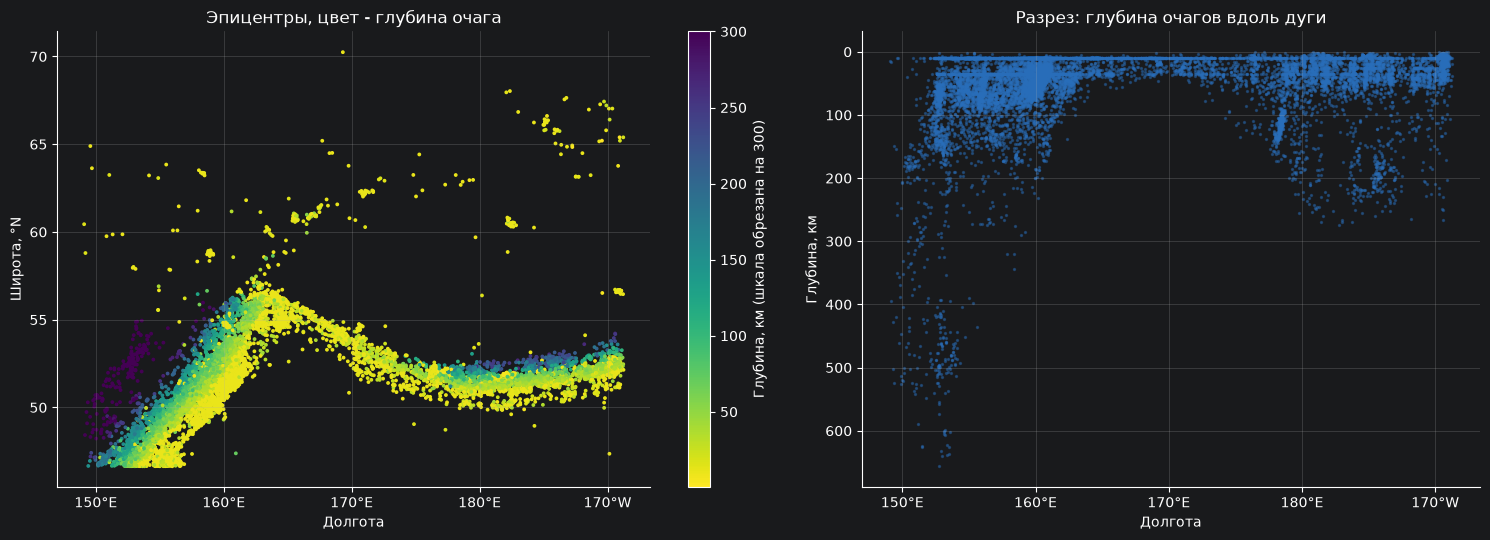

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
sc = ax[0].scatter(df["lon"], df["lat"], c=df["depth"], cmap="viridis_r", s=3, vmax=300)
ax[0].xaxis.set_major_formatter(LON_FMT)
ax[0].set_xlabel("Долгота"); ax[0].set_ylabel("Широта, °N")
ax[0].set_title("Эпицентры, цвет - глубина очага")
plt.colorbar(sc, ax=ax[0], label="Глубина, км (шкала обрезана на 300)")
ax[1].scatter(df["lon"], df["depth"], s=2, alpha=0.4, color="#2a6fbb")
ax[1].invert_yaxis(); ax[1].xaxis.set_major_formatter(LON_FMT)
ax[1].set_xlabel("Долгота"); ax[1].set_ylabel("Глубина, км")
ax[1].set_title("Разрез: глубина очагов вдоль дуги")
plt.tight_layout(); plt.show()

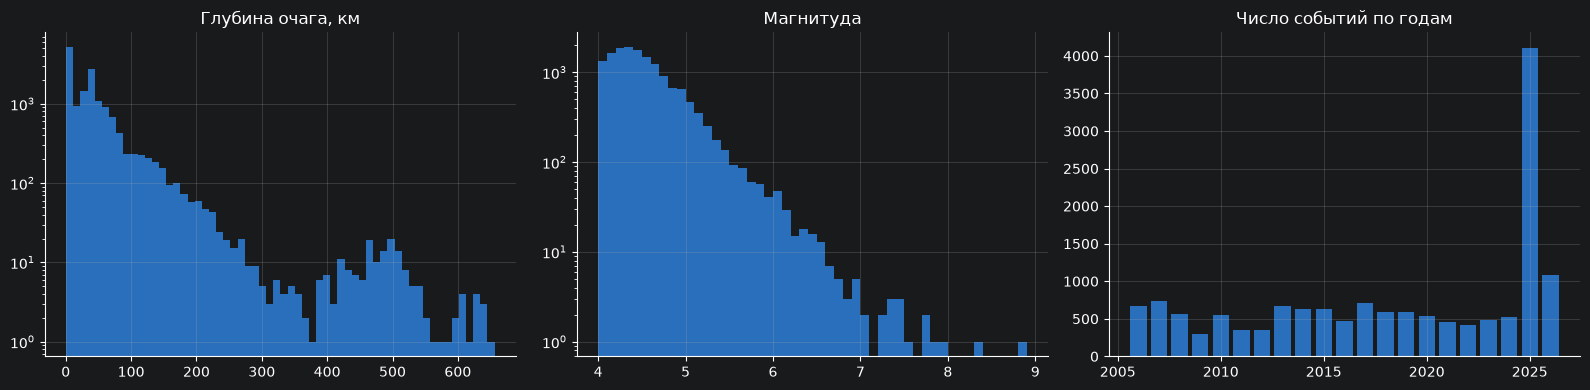

Крупнейшие события каталога:


,time,mag,depth,place
10900,2025-07-29 23:24:52.483000+00:00,8.8,35.0,"2025 Kamchatka Peninsula, Russia Earthquake"
3810,2013-05-24 05:44:48.980000+00:00,8.3,598.1,2013 Sea of Okhotsk Earthquake
4432,2014-06-23 20:53:09.700000+00:00,7.9,109.0,"Rat Islands, Aleutian Islands, Alaska"
13328,2025-09-18 18:58:14.939000+00:00,7.8,27.0,"140 km E of Petropavlovsk-Kamchatsky, Russia"
1714,2008-07-05 02:12:04.480000+00:00,7.7,632.8,Sea of Okhotsk


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(df["depth"], bins=60, color="#2a6fbb")
ax[0].set_title("Глубина очага, км"); ax[0].set_yscale("log")
ax[1].hist(df["mag"], bins=np.arange(4, 9, 0.1), color="#2a6fbb")
ax[1].set_title("Магнитуда"); ax[1].set_yscale("log")
yearly = df["year"].value_counts().sort_index()
ax[2].bar(yearly.index, yearly.values, color="#2a6fbb")
ax[2].set_title("Число событий по годам")
plt.tight_layout(); plt.show()

print("Крупнейшие события каталога:")
df.nlargest(5, "mag")[["time", "mag", "depth", "place"]]

**Что видно из данных:**

- Сейсмичность сосредоточена вдоль узкой дуги: Курилы -> Камчатка -> Командорские острова -> Алеуты.
- На разрезе видна погружающаяся под Курилы и Камчатку Тихоокеанская плита: в районе Курил и южной Камчатки очаги опускаются до 600+ км (глубокофокусные землетрясения под Охотским морем).
- Магнитуда распределена экспоненциально: почти все события имеют M 4–5.
- 2025 год выделяется резко (более 4000 событий против ~500 в обычный год): это афтершоки землетрясения M 8.8 у восточного побережья Камчатки 29.07.2025. Ровно такие всплески и должна выделять декластеризация.

## 4. Формирование признаков и нормализация

Для сейсмического районирования используем признаки, описывающие положение очага: широту, долготу и глубину.

Почему без магнитуды: магнитуда характеризует «силу» отдельного события, а не зону, где оно произошло. В одной и той же зоне происходят землетрясения любой магнитуды. Ниже проверено, что добавление магнитуды ухудшает качество разбиения (коэффициент силуэта падает).

Признаки имеют разный масштаб: широта меняется в пределах ~23°, долгота ~42°, глубина - от 0 до 650 км. Без нормализации глубина полностью определяла бы расстояния, поэтому применяем `StandardScaler` (среднее 0, стандартное отклонение 1).

In [10]:
FEATURES = ["lat", "lon", "depth"]
print("До нормализации:")
display(df[FEATURES].describe().loc[["mean", "std", "min", "max"]].round(2))

scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print("После нормализации:")
pd.DataFrame(X, columns=FEATURES).describe().loc[["mean", "std", "min", "max"]].round(2)

До нормализации:


,lat,lon,depth
mean,51.63,166.20,48.61
std,2.58,11.82,64.84
min,46.65,149.08,0.60
max,70.25,191.25,656.20


После нормализации:


,lat,lon,depth
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.93,-1.45,-0.74
max,7.23,2.12,9.37


## 5. K-means

### 5.1. Выбор числа кластеров: правило локтя и коэффициент силуэта

Коэффициент силуэта считается по случайной подвыборке из 6000 точек (`sample_size`), так как на полном наборе вычисление попарных расстояний для 15 тыс. точек занимает много времени. На результат это практически не влияет.

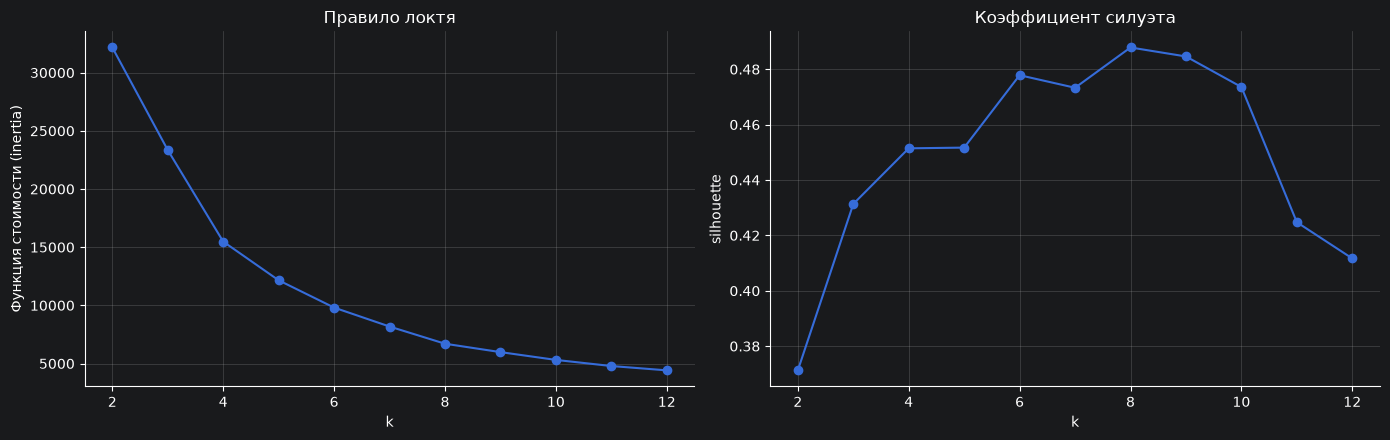

,k,inertia,silhouette
0,2,32165.0,0.371
1,3,23345.0,0.431
2,4,15478.0,0.451
3,5,12153.0,0.452
4,6,9807.0,0.478
5,7,8179.0,0.473
6,8,6701.0,0.488
7,9,5980.0,0.485
8,10,5311.0,0.474
9,11,4785.0,0.425


In [11]:
K_RANGE = range(2, 13)
inertia, silhouette = [], []
for k in K_RANGE:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X, model.labels_, sample_size=6000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(list(K_RANGE), inertia, marker="o")
ax[0].set_title("Правило локтя"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Функция стоимости (inertia)")
ax[1].plot(list(K_RANGE), silhouette, marker="o")
ax[1].set_title("Коэффициент силуэта"); ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette")
plt.tight_layout(); plt.show()

pd.DataFrame({"k": list(K_RANGE), "inertia": np.round(inertia), "silhouette": np.round(silhouette, 3)})

На графике функции стоимости «перелом» нечёткий: скорость убывания падает где-то в районе k = 4–6, и выбрать k по правилу локтя однозначно нельзя. Коэффициент силуэта даёт более чёткий ответ: максимум (≈0.49) достигается при k = 8.

In [12]:
# проверка: что будет, если добавить магнитуду в признаки
X_with_mag = StandardScaler().fit_transform(df[FEATURES + ["mag"]])
sil_mag = [silhouette_score(X_with_mag,
                            KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_with_mag),
                            sample_size=6000, random_state=RANDOM_STATE) for k in K_RANGE]
pd.DataFrame({"k": list(K_RANGE),
              "silhouette (lat, lon, depth)": np.round(silhouette, 3),
              "silhouette (+ mag)": np.round(sil_mag, 3)})

,k,"silhouette (lat, lon, depth)",silhouette (+ mag)
0,2,0.371,0.279
1,3,0.431,0.303
2,4,0.451,0.315
3,5,0.452,0.338
4,6,0.478,0.321
5,7,0.473,0.333
6,8,0.488,0.341
7,9,0.485,0.338
8,10,0.474,0.329
9,11,0.425,0.342


С магнитудой коэффициент силуэта заметно ниже при любом k: этот признак не помогает выделять зоны и только добавляет шум в расстояния.

### 5.2. Обучение модели с k = 8

In [13]:
BEST_K = 8
kmeans = KMeans(n_clusters=BEST_K, init="k-means++", n_init=10, random_state=RANDOM_STATE)
df["kmeans"] = kmeans.fit_predict(X)

# центры кластеров в исходных единицах
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES).round(1)
centers["lon"] = centers["lon"].map(lon_label)
centers

,lat,lon,depth
0,51.9,160°E,31.3
1,51.7,177°W,28.9
2,52.2,152°E,468.2
3,48.0,155°E,35.5
4,55.0,164°E,32.7
5,49.9,155°E,147.0
6,52.3,179°W,149.8
7,62.6,173°E,14.4


In [14]:
def top_place(s):
    """Самый частый ориентир из поля place (текст после 'of')."""
    return s.str.split(" of ").str[-1].value_counts().index[0]

def cluster_profile(data, col):
    prof = (data.groupby(col)
            .agg(events=("mag", "size"),
                 lat_mean=("lat", "mean"),
                 lon_mean=("lon", "mean"),
                 depth_median=("depth", "median"),
                 depth_max=("depth", "max"),
                 mag_mean=("mag", "mean"),
                 mag_max=("mag", "max"),
                 place=("place", top_place))
            .round(1))
    prof["lon_mean"] = prof["lon_mean"].map(lon_label)
    return prof

cluster_profile(df, "kmeans")

,events,lat_mean,lon_mean,depth_median,depth_max,mag_mean,mag_max,place
kmeans,,,,,,,,
0,4983,51.9,160°E,30.8,117.4,4.5,8.8,"Petropavlovsk-Kamchatsky, Russia"
1,3805,51.7,177°W,26.4,89.8,4.5,7.3,"Adak, Alaska"
2,187,52.2,152°E,476.6,656.2,4.4,8.3,"Ozernovskiy, Russia"
3,2698,48.0,155°E,35.0,114.3,4.6,7.5,"Severo-Kuril’sk, Russia"
4,2000,55.0,164°E,18.7,172.9,4.5,7.7,"Ust’-Kamchatsk Staryy, Russia"
5,817,49.9,155°E,139.6,313.3,4.4,7.2,"Severo-Kuril’sk, Russia"
6,753,52.3,179°W,133.6,285.0,4.4,7.9,"Rat Islands, Aleutian Islands, Alaska"
7,204,62.6,173°E,10.0,55.2,4.4,6.5,"Tilichiki, Russia"


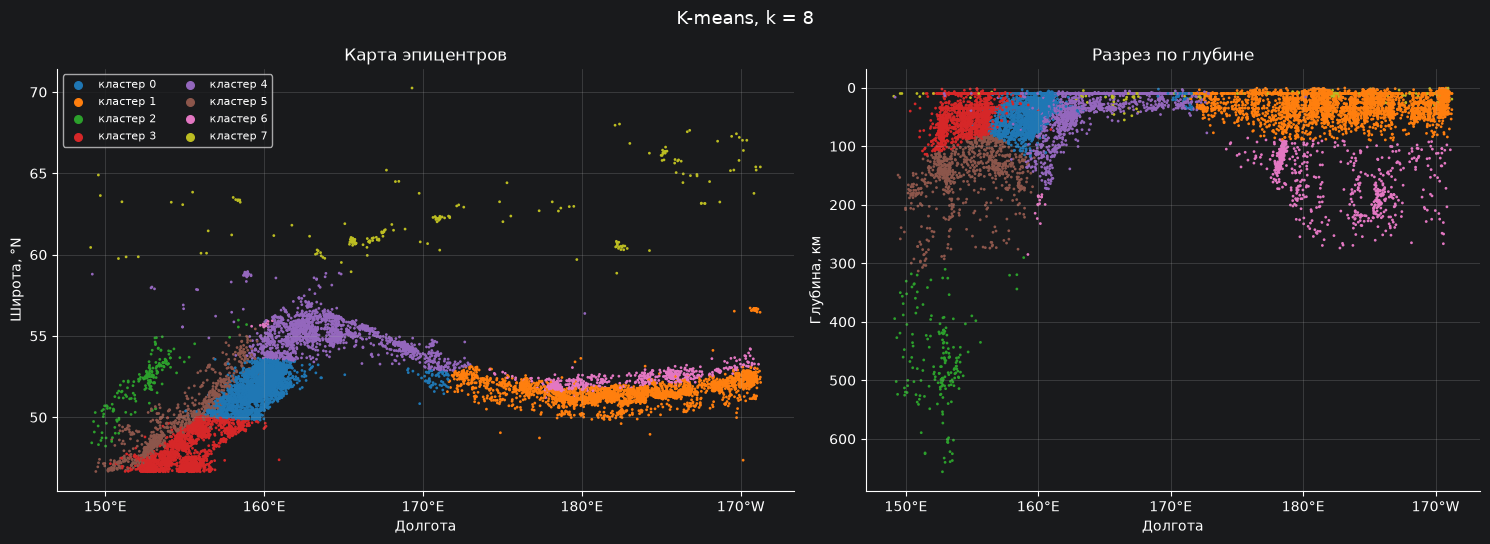

In [15]:
plot_map_and_section(df, df["kmeans"].to_numpy(), f"K-means, k = {BEST_K}")

## 6. Иерархическая агломеративная кластеризация

Иерархическая кластеризация хранит матрицу попарных расстояний: для 15 тыс. объектов это ~120 млн пар (около 1 ГБ памяти). Поэтому алгоритм обучается на случайной подвыборке из 4000 событий. Для такой задачи этого достаточно: подвыборка сохраняет пространственную структуру каталога.

Используется метод Уорда (ward): на каждом шаге объединяются два кластера, слияние которых меньше всего увеличивает внутрикластерную дисперсию. Это та же целевая функция, что и у k-means, что позволяет сравнить результаты.

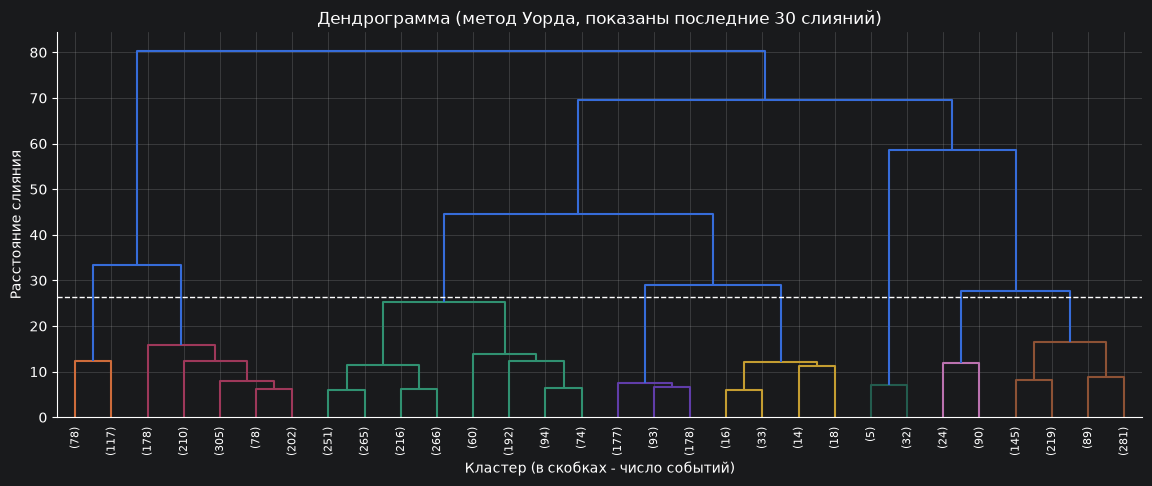

In [16]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(rng.choice(len(df), size=4000, replace=False))
X_s = X[sample_idx]
df_s = df.iloc[sample_idx].copy()

Z = linkage(X_s, method="ward")

plt.figure(figsize=(14, 5))
# уровень разреза - посередине между слияниями, дающими 8 и 7 кластеров
cut = (Z[-BEST_K, 2] + Z[-BEST_K + 1, 2]) / 2
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8,
           color_threshold=cut)
plt.axhline(cut, color="white", ls="--", lw=1)
plt.title("Дендрограмма (метод Уорда, показаны последние 30 слияний)")
plt.xlabel("Кластер (в скобках - число событий)"); plt.ylabel("Расстояние слияния")
plt.show()

Высота горизонтальных линий на дендрограмме - расстояние, на котором сливаются кластеры. Самые высокие слияния показывают крупнейшие деления каталога: сначала отделяется Алеутский сегмент от Курило-Камчатского, затем Камчатка от Курил, затем глубокофокусные очаги под Охотским морем. Пунктиром отмечен уровень разреза, дающий 8 кластеров.

Подберём число кластеров по коэффициенту силуэта и сравним разные способы связывания (linkage).

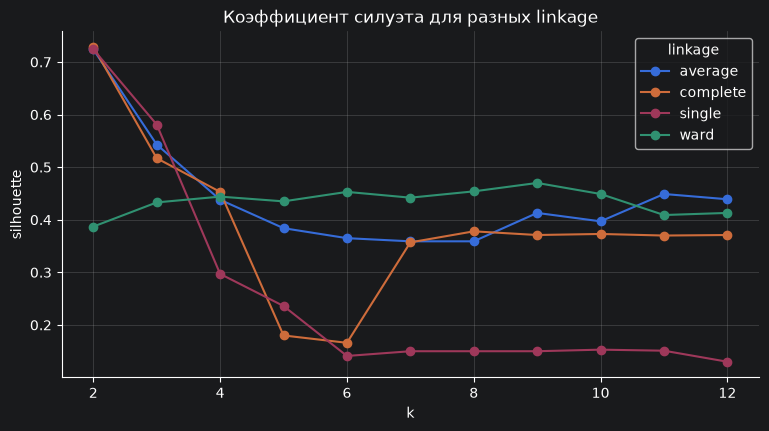

linkage,average,complete,single,ward
k,,,,
2,0.724,0.729,0.724,0.387
3,0.543,0.517,0.581,0.433
4,0.438,0.453,0.297,0.444
5,0.384,0.180,0.236,0.435
6,0.365,0.166,0.141,0.453
7,0.359,0.357,0.150,0.442
8,0.359,0.378,0.150,0.454
9,0.413,0.371,0.150,0.470
10,0.397,0.373,0.153,0.449


In [17]:
rows = []
for method in ["ward", "complete", "average", "single"]:
    for k in range(2, 13):
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X_s)
        rows.append({"linkage": method, "k": k, "silhouette": silhouette_score(X_s, labels)})
agg_scores = pd.DataFrame(rows).pivot(index="k", columns="linkage", values="silhouette").round(3)

agg_scores.plot(marker="o", figsize=(9, 4.5), title="Коэффициент силуэта для разных linkage")
plt.ylabel("silhouette"); plt.show()
agg_scores

- При k = 2 у `average`, `complete` и `single` очень высокий силуэт (≈0.72), но это обманчиво: они просто отделяют ~40 глубокофокусных событий (~490 км) от всей остальной дуги. Формально эти группы далеко друг от друга, но содержательно такое разбиение бесполезно.
- `single` (расстояние между ближайшими точками) склонен к «цепочечному эффекту»: почти вся дуга связывается в один кластер, а остальные кластеры - единичные удалённые точки.
- `ward` даёт сбалансированные и интерпретируемые кластеры, его и используем, с тем же k = 8 для сравнения с k-means.

In [18]:
for method in ["single", "ward"]:
    labels = AgglomerativeClustering(n_clusters=BEST_K, linkage=method).fit_predict(X_s)
    print(f"{method:>7}: размеры кластеров {np.sort(np.bincount(labels))[::-1]}")

 single: размеры кластеров [3935   37   14   10    1    1    1    1]
   ward: размеры кластеров [1418  973  734  448  195  114   81   37]


In [19]:
agg = AgglomerativeClustering(n_clusters=BEST_K, linkage="ward")
df_s["agg"] = agg.fit_predict(X_s)

print("Согласованность с k-means на той же подвыборке (Adjusted Rand Index):",
      round(adjusted_rand_score(df_s["kmeans"], df_s["agg"]), 3))
cluster_profile(df_s, "agg")

Согласованность с k-means на той же подвыборке (Adjusted Rand Index): 0.832


,events,lat_mean,lon_mean,depth_median,depth_max,mag_mean,mag_max,place
agg,,,,,,,,
0,1418,52.1,160°E,35.0,199.4,4.5,7.2,"Petropavlovsk-Kamchatsky, Russia"
1,734,48.2,155°E,35.0,97.8,4.5,6.5,"Severo-Kuril’sk, Russia"
2,195,52.2,178°W,130.8,269.6,4.4,6.5,"Rat Islands, Aleutian Islands, Alaska"
3,114,48.4,153°E,151.6,319.6,4.4,6.0,Kuril Islands
4,973,51.7,177°W,26.9,88.3,4.4,7.3,"Adak, Alaska"
5,81,61.1,173°E,10.0,44.3,4.5,5.6,"Tilichiki, Russia"
6,448,55.0,164°E,10.0,88.7,4.5,6.3,"Ust’-Kamchatsk Staryy, Russia"
7,37,52.6,153°E,486.1,656.2,4.5,7.7,"Ozernovskiy, Russia"


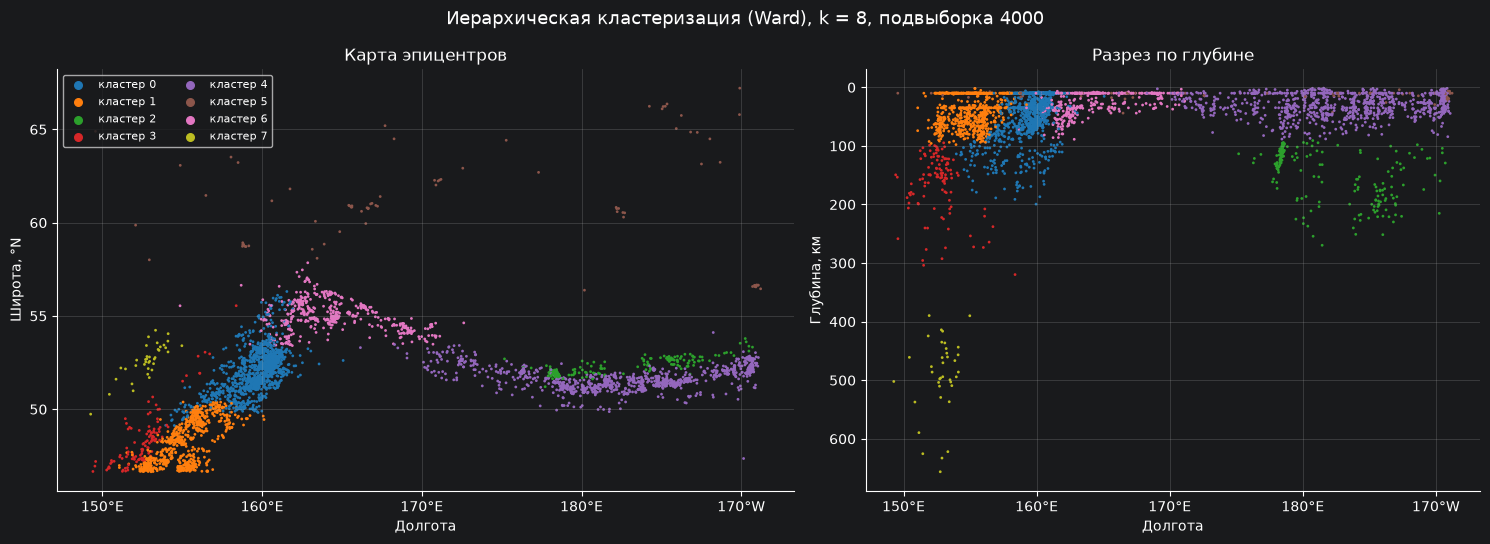

In [20]:
plot_map_and_section(df_s, df_s["agg"].to_numpy(), f"Иерархическая кластеризация (Ward), k = {BEST_K}, подвыборка 4000")

## 7. DBSCAN

### 7.1. Пространственный DBSCAN (районирование)

Параметры DBSCAN: радиус окрестности `eps` и минимальное число соседей `min_samples`. Число кластеров алгоритм определяет сам.

Для подбора `eps` строится график k-расстояний: для каждой точки находится расстояние до её k-го ближайшего соседа (k = `min_samples`), значения сортируются. Точка «излома» кривой - разумное значение `eps`: левее лежат точки плотных областей, правее - разреженные точки (будущий шум).

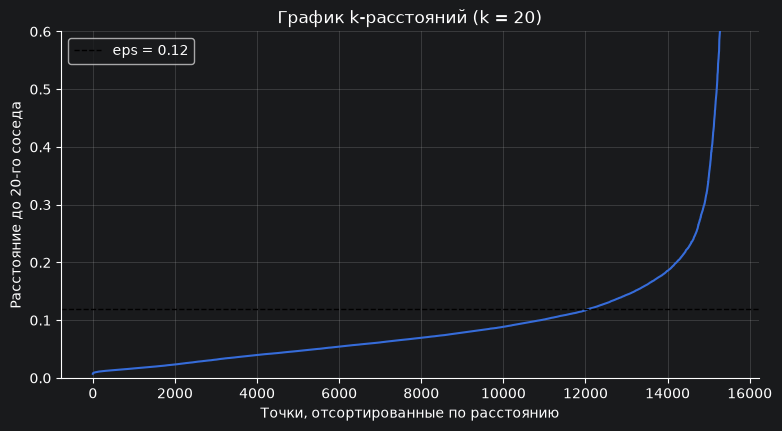

In [21]:
MIN_SAMPLES = 20
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
k_dist = np.sort(nn.kneighbors(X)[0][:, -1])

plt.figure(figsize=(9, 4.5))
plt.plot(k_dist)
plt.axhline(0.12, color="black", ls="--", lw=1, label="eps = 0.12")
plt.ylim(0, 0.6)
plt.title(f"График k-расстояний (k = {MIN_SAMPLES})")
plt.xlabel("Точки, отсортированные по расстоянию"); plt.ylabel(f"Расстояние до {MIN_SAMPLES}-го соседа")
plt.legend(); plt.show()

In [22]:
rows = []
for eps in [0.08, 0.10, 0.12, 0.15, 0.20]:
    for ms in [10, 20]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = labels != -1
        n_clusters = labels.max() + 1
        sil = silhouette_score(X[mask], labels[mask], sample_size=6000, random_state=RANDOM_STATE) if n_clusters > 1 else np.nan
        sizes = np.sort(np.bincount(labels[mask]))[::-1]
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_clusters,
                     "noise_share": round(1 - mask.mean(), 3),
                     "silhouette": round(sil, 3),
                     "largest_cluster_share": round(sizes[0] / mask.sum(), 2)})
pd.DataFrame(rows)

,eps,min_samples,clusters,noise_share,silhouette,largest_cluster_share
0,0.08,10,44,0.175,-0.128,0.55
1,0.08,20,28,0.285,0.236,0.43
2,0.10,10,29,0.110,-0.122,0.56
3,0.10,20,24,0.195,-0.099,0.57
4,0.12,10,28,0.073,-0.304,0.95
5,0.12,20,13,0.136,0.146,0.58
6,0.15,10,16,0.045,0.107,0.97
7,0.15,20,10,0.088,0.017,0.97
8,0.20,10,13,0.026,0.169,0.98
9,0.20,20,8,0.046,0.194,0.97


Резкий излом на графике k-расстояний находится около 0.2, но при таком `eps` ~97% событий сливаются в один кластер на всю дугу: сейсмичность вдоль дуги почти непрерывна. Поэтому выбираем значение в начале изгиба кривой: `eps = 0.12`, `min_samples = 20`. При этом около 14% событий уходят в шум, а крупные сегменты дуги разделяются. При меньшем `eps` шума становится 20–30% и появляются десятки мелких кластеров.

In [23]:
dbscan = DBSCAN(eps=0.12, min_samples=MIN_SAMPLES)
df["dbscan"] = dbscan.fit_predict(X)
print("Кластеров:", df["dbscan"].max() + 1, "| доля шума:", round((df["dbscan"] == -1).mean(), 3))
cluster_profile(df, "dbscan")

Кластеров: 13 | доля шума: 0.136


,events,lat_mean,lon_mean,depth_median,depth_max,mag_mean,mag_max,place
dbscan,,,,,,,,
-1,2098,52.9,166°E,115.8,656.2,4.4,8.3,"Severo-Kuril’sk, Russia"
0,7754,50.6,158°E,33.6,103.9,4.5,8.8,"Petropavlovsk-Kamchatsky, Russia"
1,3557,51.6,177°W,33.8,150.6,4.5,7.9,"Adak, Alaska"
2,919,55.0,166°E,10.0,29.9,4.5,7.7,"Ust’-Kamchatsk Staryy, Russia"
3,429,55.4,163°E,39.4,74.0,4.4,6.4,"Ust’-Kamchatsk Staryy, Russia"
4,30,60.8,166°E,10.0,19.8,4.5,5.1,"Tilichiki, Russia"
5,244,51.9,176°E,10.0,19.1,4.4,6.4,"Attu Station, Alaska"
6,104,52.6,172°E,10.0,19.8,4.4,6.0,"Attu Station, Alaska"
7,141,48.2,153°E,143.6,165.6,4.4,5.3,Kuril Islands


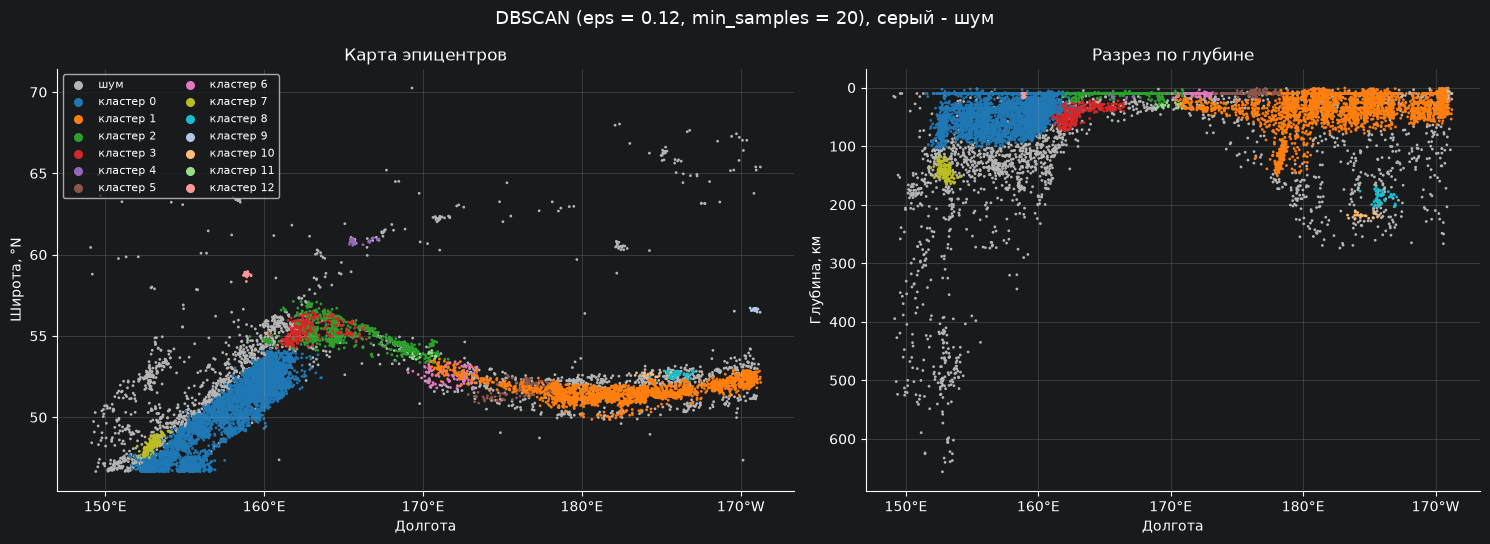

In [24]:
plot_map_and_section(df, df["dbscan"].to_numpy(), "DBSCAN (eps = 0.12, min_samples = 20), серый - шум")

**Особенности результата DBSCAN:**

- Курилы и Камчатка объединились в один большой кластер. Сейсмичность вдоль дуги непрерывна, и DBSCAN связывает соседние участки через плотные «перемычки». Это известный недостаток алгоритма, упомянутый в методичке.
- Зато DBSCAN не навязывает «круглую» форму: кластеры вытянуты вдоль дуги, как реальные сейсмогенные зоны.
- Глубокие и промежуточные очаги заметно разреженнее мелких, поэтому в основном ушли в шум (медианная глубина шумовых событий ~115 км). Глубокофокусная зона под Охотским морем (~480 км), которую k-means выделил отдельным кластером, здесь вообще не стала кластером. Это ограничение единого порога плотности для всего набора.
- Мелкие отдельные кластеры соответствуют локальным очагам повышенной активности.

### 7.2. Пространственно-временной DBSCAN: выделение серий афтершоков (декластеризация)

Здесь DBSCAN применяется к той задаче, где он особенно полезен. Признаки: координаты эпицентра в километрах и время в днях. Каждый признак делится на свой «характерный масштаб»:

- 50 км по горизонтали,
- 30 дней по времени.

После такого масштабирования `eps = 1` означает «события ближе ~50 км и ~30 дней друг к другу считаются соседями». Плотная группа событий в пространстве и времени - серия (афтершоки или рой), а одиночные события, отнесённые к шуму, - **фоновая сейсмичность**.

Здесь используется не `StandardScaler`, а масштабирование по физическому смыслу: стандартизация сделала бы окно по времени равным примерно 7 годам, что не имеет смысла для афтершоков.

In [25]:
R_KM, T_DAYS = 50, 30
lat0, lon0 = df["lat"].mean(), df["lon"].mean()
x_km = (df["lon"] - lon0) * 111.2 * np.cos(np.radians(df["lat"]))
y_km = (df["lat"] - lat0) * 111.2
X_st = np.column_stack([x_km / R_KM, y_km / R_KM, df["days"] / T_DAYS])

df["sequence"] = DBSCAN(eps=1.0, min_samples=10).fit_predict(X_st)
df["is_background"] = df["sequence"] == -1

print("Найдено серий:", df["sequence"].max() + 1)
print("Доля событий в сериях:", round((~df["is_background"]).mean(), 3))
print("Доля фоновых событий:", round(df["is_background"].mean(), 3))

Найдено серий: 82
Доля событий в сериях: 0.489
Доля фоновых событий: 0.511


In [26]:
seq = (df[~df["is_background"]]
       .groupby("sequence")
       .agg(events=("mag", "size"),
            start=("time", "min"),
            end=("time", "max"),
            mag_max=("mag", "max"),
            place=("place", top_place))
       .sort_values("events", ascending=False))
seq["duration_days"] = (seq["end"] - seq["start"]).dt.days
seq["start"] = seq["start"].dt.date
seq["end"] = seq["end"].dt.date
seq.head(10)

,events,start,end,mag_max,place,duration_days
sequence,,,,,,
72,4037,2025-06-19,2026-10-28,8.8,"Petropavlovsk-Kamchatsky, Russia",495
0,832,2006-10-21,2007-09-12,6.4,the Kuril Islands,325
22,171,2013-05-16,2013-06-20,6.1,"Petropavlovsk-Kamchatsky, Russia",34
44,161,2017-07-17,2017-09-15,7.7,"Komandorskiye Ostrova, Russia region",60
47,153,2018-11-25,2019-02-21,7.3,"Ust’-Kamchatsk Staryy, Russia",88
76,135,2026-03-02,2026-09-04,6.4,"Attu Station, Alaska",185
27,129,2014-06-23,2014-10-19,7.9,"Rat Islands, Aleutian Islands, Alaska",117
24,123,2013-08-30,2013-11-07,7.0,"Atka, Alaska",68
12,112,2010-07-17,2010-08-27,6.7,"Nikolski, Alaska",41


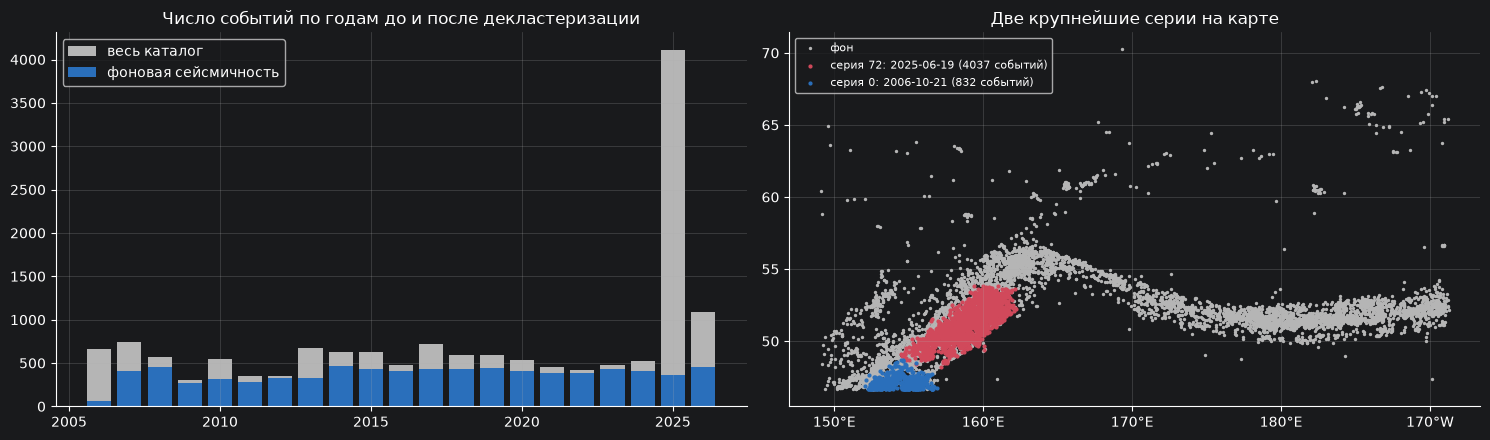

2006 г. в каталоге неполный (данные начинаются с октября).


,весь каталог,фон
year,,
2006,665,57
2007,739,412
2008,566,454
2009,299,273
2010,546,321
2011,355,276
2012,349,331
2013,670,333
2014,632,469


In [27]:
yearly_all = df["year"].value_counts().sort_index()
yearly_bg = df.loc[df["is_background"], "year"].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(yearly_all.index, yearly_all.values, color="#B5B5B5", label="весь каталог")
ax[0].bar(yearly_bg.index, yearly_bg.values, color="#2a6fbb", label="фоновая сейсмичность")
ax[0].set_title("Число событий по годам до и после декластеризации")
ax[0].legend()

top_ids = seq.index[:2]
bg = df[df["is_background"]]
ax[1].scatter(bg["lon"], bg["lat"], s=2, color=NOISE_COLOR, label="фон")
palette = ["#d1495b", "#2a6fbb"]
for color, sid in zip(palette, top_ids):
    part = df[df["sequence"] == sid]
    ax[1].scatter(part["lon"], part["lat"], s=4, color=color,
                  label=f"серия {sid}: {seq.loc[sid, 'start']} ({len(part)} событий)")
ax[1].xaxis.set_major_formatter(LON_FMT)
ax[1].set_title("Две крупнейшие серии на карте"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("2006 г. в каталоге неполный (данные начинаются с октября).")
pd.DataFrame({"весь каталог": yearly_all, "фон": yearly_bg})

После удаления серий число фоновых событий по годам практически постоянно: в 2025 г. всплеск в ~4100 событий исчезает, остаётся уровень, обычный для региона. Крупнейшая выделенная серия (~4000 событий) - землетрясение M 8.8 у Камчатки 29.07.2025 с форшоками (с июня 2025 г.) и афтершоками, которые продолжаются до конца каталога. Вторая (~830 событий, 2006–2007 гг.) - на Средних Курилах; по времени и месту это афтершоки Симуширских землетрясений M 8.3 (ноябрь 2006 г.) и M 8.1 (январь 2007 г.), главные толчки которых лежат чуть южнее границы выгрузки (46.6° с.ш.). Остальные крупные серии тоже привязаны к сильным событиям: Командорские острова (M 7.7, 2017), Крысьи острова (M 7.9, 2014) и др.

Именно такой «очищенный» каталог используется при оценке сейсмической опасности: он показывает, сколько независимых землетрясений происходит в регионе, без искажения от афтершоков.

## 8. Визуализация: трёхмерное пространство признаков и t-SNE

У каждого события всего три признака (широта, долгота, глубина), поэтому понижать размерность для визуализации не нужно: точки можно показать прямо в исходном трёхмерном пространстве. Оси подписаны в исходных единицах (градусы и километры). От нормализованного пространства, в котором работали алгоритмы, они отличаются только масштабом по каждой оси, поэтому взаимное расположение кластеров то же самое. Ось глубины направлена вниз.

t-SNE строится по подвыборке из 4000 событий (на полном наборе он работает долго).

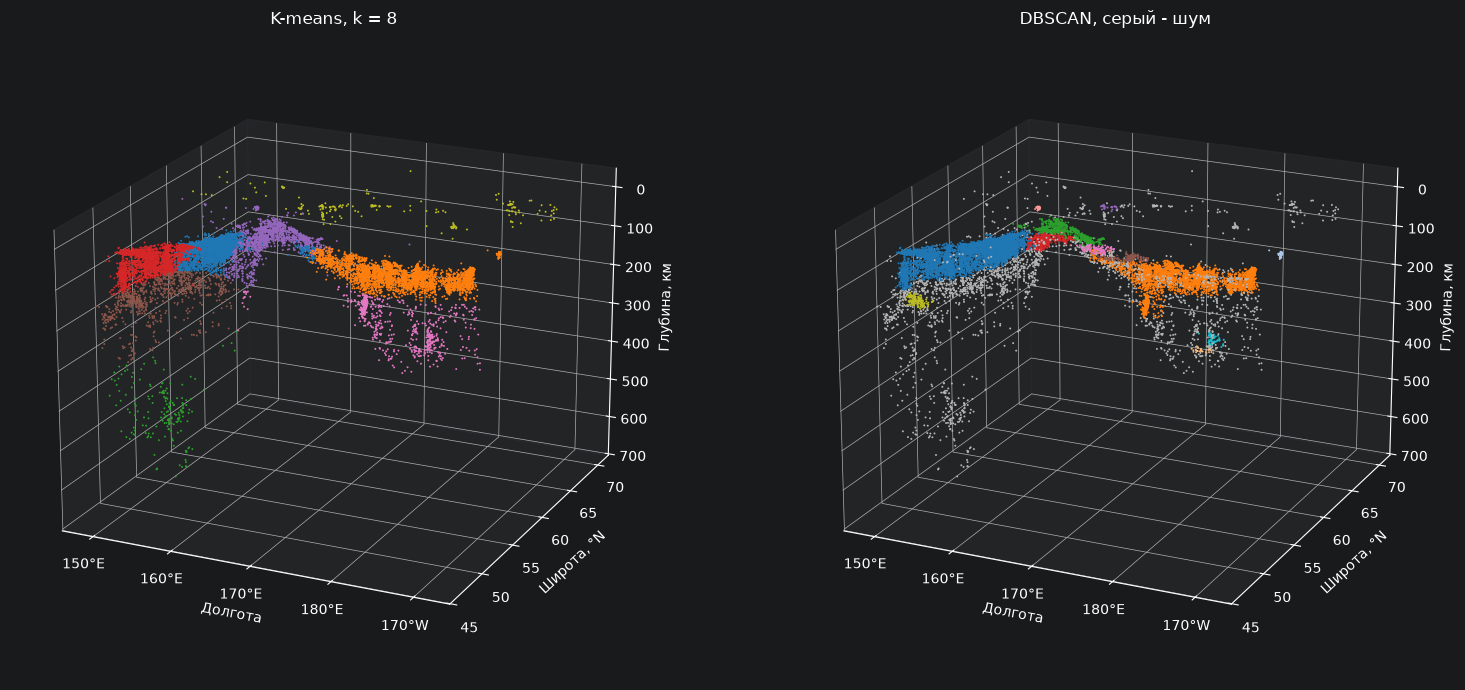

In [28]:
fig = plt.figure(figsize=(16, 7))
for i, (col, title) in enumerate([("kmeans", f"K-means, k = {BEST_K}"),
                                  ("dbscan", "DBSCAN, серый - шум")], start=1):
    labels = df[col].to_numpy()
    order = np.argsort(labels != -1)          # шум рисуем первым, под кластерами
    d = df.iloc[order]
    ax = fig.add_subplot(1, 2, i, projection="3d")
    ax.scatter(d["lon"], d["lat"], d["depth"], c=to_rgba_array(cluster_colors(labels[order])), s=2, linewidths=0, depthshade=False)
    ax.invert_zaxis()
    ax.xaxis.set_major_formatter(LON_FMT)
    ax.set_xlabel("Долгота"); ax.set_ylabel("Широта, °N"); ax.set_zlabel("Глубина, км")
    ax.view_init(elev=20, azim=-65)
    ax.set_title(title)
plt.tight_layout(); plt.show()

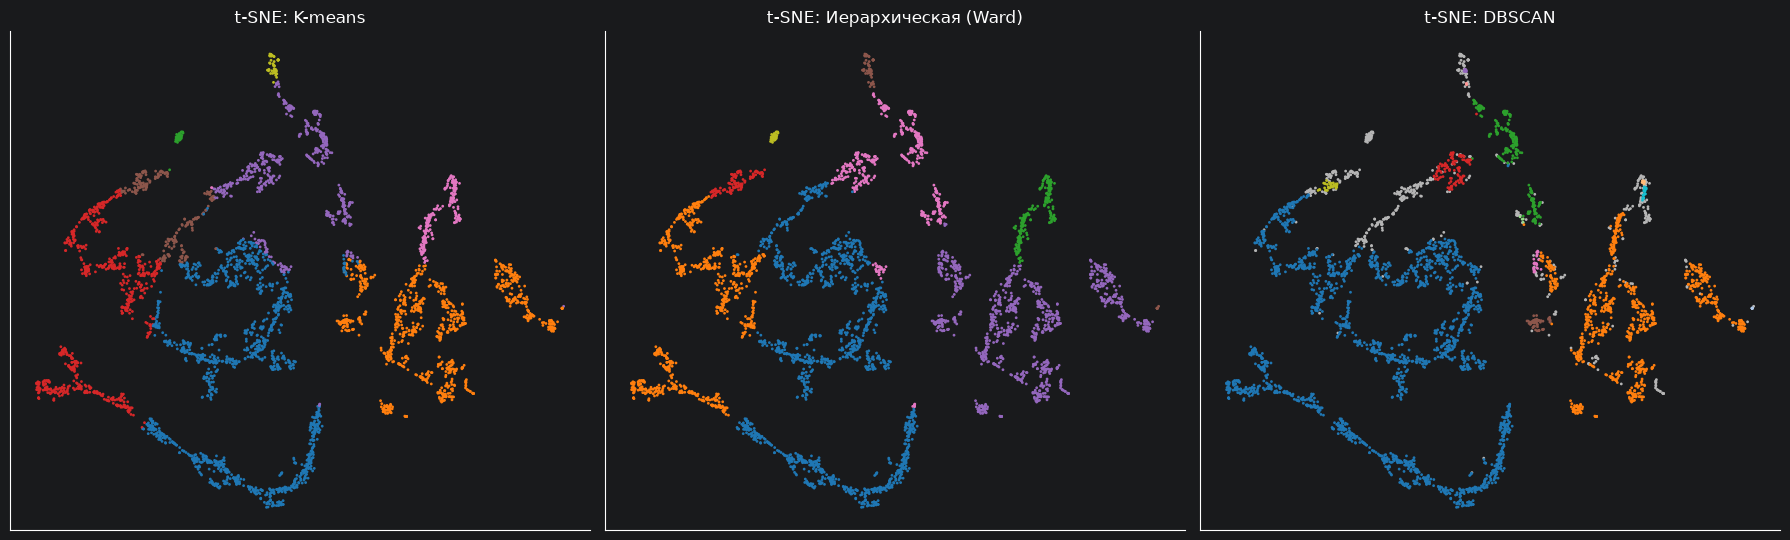

In [29]:
# метки DBSCAN для той же подвыборки, что использовалась в иерархической кластеризации
df_s["dbscan"] = df["dbscan"].to_numpy()[sample_idx]

tsne = TSNE(n_components=2, perplexity=40, init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_s)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for a, labels, title in [
    (ax[0], df_s["kmeans"].to_numpy(), "K-means"),
    (ax[1], df_s["agg"].to_numpy(), "Иерархическая (Ward)"),
    (ax[2], df_s["dbscan"].to_numpy(), "DBSCAN"),
]:
    order = np.argsort(labels != -1)
    a.scatter(X_tsne[order, 0], X_tsne[order, 1], c=cluster_colors(labels[order]), s=4, linewidths=0)
    a.set_title(f"t-SNE: {title}"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

t-SNE сохраняет локальное соседство, поэтому на нём лучше видна «нитевидная» структура дуги: протяжённые ленты соответствуют сегментам дуги, а компактные группы - глубокофокусным и локальным очагам. Кластеры k-means и Ward нарезают ленты на куски, а DBSCAN следует их форме.

## 9. Сравнение методов

In [30]:
def metrics(Xm, labels):
    mask = labels != -1
    return {"clusters": labels.max() + 1,
            "noise_share": round(1 - mask.mean(), 3),
            "silhouette": round(silhouette_score(Xm[mask], labels[mask]), 3),
            "davies_bouldin": round(davies_bouldin_score(Xm[mask], labels[mask]), 3)}

comparison = pd.DataFrame({
    "K-means (k=8)": metrics(X_s, df_s["kmeans"].to_numpy()),
    "Иерархическая Ward (k=8)": metrics(X_s, df_s["agg"].to_numpy()),
    "DBSCAN (eps=0.12, ms=20)": metrics(X_s, df_s["dbscan"].to_numpy()),
}).T
print("Метрики посчитаны на одной и той же подвыборке из 4000 событий.")
comparison

Метрики посчитаны на одной и той же подвыборке из 4000 событий.


,clusters,noise_share,silhouette,davies_bouldin
K-means (k=8),8.0,0.000,0.484,0.710
Иерархическая Ward (k=8),8.0,0.000,0.454,0.691
"DBSCAN (eps=0.12, ms=20)",13.0,0.134,0.140,0.649


- По коэффициенту силуэта лучший k-means, Ward немного уступает, DBSCAN сильно отстаёт. Силуэт рассчитан на компактные «шарообразные» кластеры и занижает оценку вытянутых кластеров DBSCAN.
- По индексу Дэвиса - Болдина (чем меньше, тем лучше) DBSCAN формально лучший, но он считается только по точкам вне шума: самые «трудные» 13% событий из оценки исключены.

## 10. Выводы

1. **Данные.** Каталог USGS из 15 447 землетрясений (M ≥ 4.0, 2006–2026) по Курило-Камчатской и Алеутской дугам. Предобработка: удалены служебные колонки, долгота «развёрнута» через линию перемены дат, признаки нормализованы `StandardScaler`, так как глубина (0–650 км) и координаты (десятки градусов) имеют разный масштаб.

2. **K-means.** Правило локтя не дало явного перелома, оптимальное число кластеров определено по коэффициенту силуэта: k = 8 (≈0.49). По правилу локтя перелом нечёткий. Кластеры хорошо интерпретируются как сейсмогенные зоны: мелкофокусная зона субдукции у Камчатки и у Северных Курил, Алеутская мелкофокусная зона, промежуточные глубины (~140 км) под Курилами и Алеутами, глубокофокусная зона под Охотским морем (~480 км), стык Камчатской и Алеутской дуг (Командоры, Усть-Камчатск), внутриплитовая сейсмичность Корякии. Добавление магнитуды в признаки ухудшает разбиение.

3. **Иерархическая кластеризация (Ward).** Обучена на подвыборке 4000 событий из-за квадратичных затрат памяти. Дендрограмма показывает иерархию: первым делением отделяется Алеутский сегмент от Курило-Камчатского, затем выделяются глубокие очаги. Результат близок к k-means (ARI ≈ 0.83), что ожидаемо: оба метода минимизируют внутрикластерную дисперсию. Связывание `single` даёт цепочечный эффект и бесполезное разбиение.

4. **DBSCAN.** Параметр `eps` подобран по графику k-расстояний и таблице перебора: формальный излом (~0.2) сливает всю дугу в один кластер, поэтому выбрано меньшее значение 0.12. Алгоритм сам определяет число кластеров и выделяет шум, кластеры повторяют вытянутую форму дуги. Недостатки проявились наглядно: непрерывная дуга Курилы - Камчатка слилась в один кластер через плотные «перемычки», а разреженные глубокие очаги ушли в шум из-за единого порога плотности.

5. **Прикладной результат.** Пространственно-временной DBSCAN решает задачу декластеризации каталога: около половины событий (49%) отнесены к 82 сериям, крупнейшие из них - землетрясение M 8.8 у Камчатки (2025) с афтершоками и афтершоки Симуширских землетрясений на Курилах (2006–2007). После их исключения фоновая сейсмичность по годам почти постоянна, то есть всплеск 2025 г. полностью объясняется одной серией афтершоков.

6. **Какой метод для чего подходит.** Для районирования по зонам с разной глубиной очагов удобнее k-means и Ward: они дают понятные компактные зоны. Для выделения серий и отделения фона лучше всего подходит DBSCAN, так как число серий заранее неизвестно, их форма произвольна, а одиночные события естественно становятся шумом.